# contextual plot noteboor
this notebook focuses on plotting context figures for publication 
- number of FUAs included in analysis 
- number of itineraries gathered
- number of shortest itineraries gathered
- distance coverage of itineraries by adjacency
- max reach by FuA (check diff with base and shortest?)

In [2]:
# --- FUA spatial distribution map ( Europe) ---
%load_ext autoreload
%autoreload 1
%aimport lib.utils_plotting
from lib.utils_plotting import make_basemap, set_nodesize_logscale
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline
import numpy as np
import pandas as pd
import colorcet as cet
import seaborn as sns

DATA_DIR = Path("inputs")
OUTPUT_VERSION = "v2"
IN_DIR = Path(f"outputs/{OUTPUT_VERSION}/intermediate")
OUT_DIR = Path(f"outputs/{OUTPUT_VERSION}/itineraries-plot")
assert IN_DIR.is_dir()
OUT_DIR.mkdir(parents=True, exist_ok=True)

it_base_df = pd.read_parquet(
    IN_DIR/"itineraries-enriched.parquet")
it_shortest_df = pd.read_parquet(
    IN_DIR/"shortest-itineraries.parquet")
fua_gdf = gpd.read_parquet(DATA_DIR/"fuas.parquet")
basemap_gdf = gpd.read_file(DATA_DIR/Path("maps/ne_110m_admin_0_countries"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
len(set(it_base_df["fua_src"].unique()) | set(
    it_base_df["fua_trg"].unique()))

366

## FUAs present
- number of FUAs present per country, plot by popsize?
- plot as circular dot (as template?)

In [4]:


# make utils_plotting importable from project root
PROJECT_ROOT = Path("../../").resolve()
if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(0, str(PROJECT_ROOT))

# Manual override: countries whose FUAs are excluded (ISO alpha-2). Fill as needed.
EXCLUDE_COUNTRIES = ["BG", "CY", "EL", "IE",
                     "EE", "FI", "MT", "LT", "LV", "RO"]
EXCLUDE_FUAS = [
    54,  # belfast
    447,  # Palma de Mallorca
]

# --- 1. Data prep ---
fua_plot = fua_gdf[(~fua_gdf["icc"].isin(EXCLUDE_COUNTRIES)
                    & (~fua_gdf["fua_id"].isin(EXCLUDE_FUAS)))].copy()
# fua_plot = fua_plot.to_crs(epsg=3035)  # LAEA Europe

# --- 2. Marker size (log-scaled to fixed pt range) ---
sizes, _ = set_nodesize_logscale(fua_plot["popu"], min_size=5.0, max_size=60.0)
fua_plot["marker_size"] = sizes

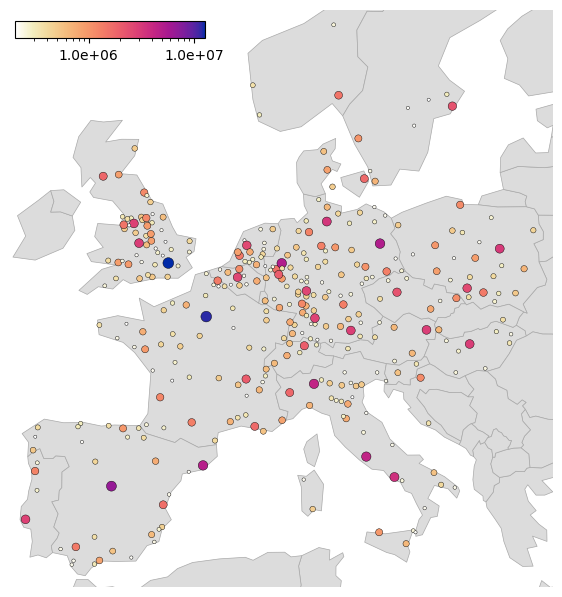

In [5]:

# ---  ️3. Basemap + plot ---
basemap_path = Path("../../data/maps/ne_110m_admin_0_countries")
fig, ax = make_basemap(basemap_path, crs=fua_plot.crs,
                       bounds_source=fua_plot, figsize=(7, 7.5), pad_frac=0.02)
sc = ax.scatter(
    fua_plot.centre.x,
    fua_plot.centre.y,
    s=fua_plot["marker_size"],
    c=fua_plot["popu"],
    norm=LogNorm(vmin=fua_plot["popu"].min(), vmax=fua_plot["popu"].max()),
    cmap="cet_linear_worb_100_25_c53",
    edgecolor="black",
    linewidth=0.3,
    # zorder=20,
)

# colorbar in thousands of inhabitants, scientific notation
# (x, y, w, h) in axes fractions
cbar_ax = ax.inset_axes([0.01, 0.95, 0.35, 0.03])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal")
# cbar.set_label("Population")
cbar.ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.1e}")
)

# ax.set_title(
#     f"FUAs included in analysis, shaded by population size (n = {len(fua_plot):,})")
ax.set_axis_off()

# --- 4. Output ---
fig.savefig(OUT_DIR / "fua_distribution_map.jpg", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "fua_distribution_map.pdf", bbox_inches="tight")
plt.show()

## itineraries gathered 
this should cover number of ODs in domestic and neighboring international

## max reach


In [6]:
# --- Max reach: per-FUA max adjacency over direct (n_trans==0) itineraries ---
from matplotlib.patches import Patch
from shapely.geometry import LineString
import matplotlib as mpl

METRIC = None

figsize_custom = (7, 7.5)
mpl.rcParams["figure.figsize"] = figsize_custom


def _max_reach(df):
    direct = df[df["n_trans"] == 0]
    return direct.groupby("fua_src")["adjacency"].max()


reach_base = _max_reach(it_base_df)
reach_short = _max_reach(it_shortest_df)

# --- Compare ibase vs ishort reach ---
reach_cmp = pd.DataFrame(
    {"reach_base": reach_base, "reach_short": reach_short})
reach_cmp["delta"] = reach_cmp["reach_base"] - reach_cmp["reach_short"]
# NaN-aware mismatch mask (naive != treats NaN as unequal)
mismatch = (
    (reach_cmp["reach_base"].isna() != reach_cmp["reach_short"].isna())
    | (reach_cmp["reach_base"].fillna(-1) != reach_cmp["reach_short"].fillna(-1))
)
reach_diff = reach_cmp[mismatch].copy()
print(f"FUAs with differing reach (ibase vs ishort): {len(reach_diff)}")
display(reach_diff)

# --- Plot data prep (ishort reach) ---
reach_plot = fua_gdf[["fua_id", "icc", "centre"]].copy()
reach_plot = gpd.GeoDataFrame(reach_plot, geometry="centre", crs=fua_gdf.crs)
reach_plot["reach"] = reach_plot["fua_id"].map(
    reach_short).astype(pd.Int16Dtype())
reach_plot["reach_base"] = reach_plot["fua_id"].map(
    reach_base).astype(pd.Int16Dtype())

# apply same exclusions as the FUA map cell
reach_plot = reach_plot[
    (~reach_plot["icc"].isin(EXCLUDE_COUNTRIES))
    & (~reach_plot["fua_id"].isin(EXCLUDE_FUAS))
].copy()

# linear marker size over observed reach range
# min_size, max_size = 6.0, 40.0

reach_range = range(int(reach_plot["reach_base"].max())+1)
marker_size_increment = 9
marker_sizes = {reach: marker_size_increment *
                (reach+1) for reach in reach_range}

FUAs with differing reach (ibase vs ishort): 14


,reach_base,reach_short,delta
fua_src,,,
24,2,1,1
91,1,0,1
190,2,1,1
245,2,1,1
257,2,1,1
266,3,1,2
336,2,1,1
341,2,1,1
345,2,1,1


In [7]:
marker_sizes

{0: 9, 1: 18, 2: 27, 3: 36}

In [8]:
reach_plot[reach_plot.reach_base.isna()]

,fua_id,icc,centre,reach,reach_base
id,,,,,
13,13,ES,POINT (-2.43799 36.85112),<NA>,<NA>
59,59,NO,POINT (5.30077 60.38354),<NA>,<NA>
113,113,IT,POINT (9.11633 39.26673),<NA>,<NA>
124,124,IT,POINT (15.06763 37.54193),<NA>,<NA>
278,278,ES,POINT (-6.11681 36.69379),<NA>,<NA>
372,372,ES,POINT (-4.78162 36.52633),<NA>,<NA>
382,382,IT,POINT (15.52534 38.18938),<NA>,<NA>
446,446,IT,POINT (13.34722 38.11037),<NA>,<NA>
459,459,IT,POINT (12.35283 43.08666),<NA>,<NA>


342


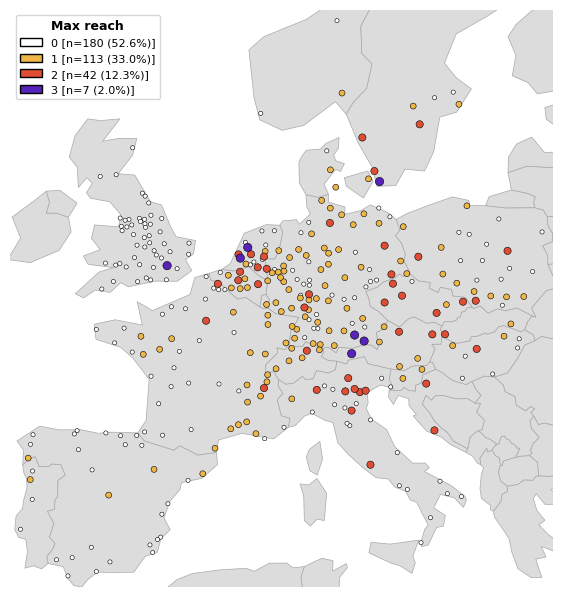

In [9]:

# --- Basemap + plot ---
fig, ax = make_basemap(basemap_path, crs=reach_plot.crs,
                       bounds_source=reach_plot, figsize=figsize_custom, pad_frac=0.02)

# --- Fixed 4-colour reach map (reach 0-3); tune hex codes as needed ---
REACH_COLORS = ["#ffffff", "#EEB646", "#df4d34", "#5723b9"]  # reach 0,1,2,3
color_map = {0: REACH_COLORS[0], 1: REACH_COLORS[1],
             2: REACH_COLORS[2], 3: REACH_COLORS[3]}
reach_categories = sorted(color_map.keys())
legend_handles = []

# guard: reach must not exceed the fixed palette
if reach_plot["reach"].dropna().max() > 3:
    raise ValueError(
        f"Max reach {reach_plot['reach'].dropna().max()} exceeds fixed palette (0-3)"
    )

# --- OD direction lines: unique international pairs (adjacency > 0) ---
# todo: modify the direction lines for only adjacency > 0 fuas, not ods

_plot = it_base_df  # note that the points need a separate adjustment
_plot_metric = "reach_base"
_adjacency_line_thres = 2
od_lines = (
    _plot[
        (_plot.fua_src.isin(
            reach_plot[reach_plot[_plot_metric] >= _adjacency_line_thres].index))
        & (_plot.adjacency >= _adjacency_line_thres)
        & (_plot.n_trans == 0)
    ]
    [["fua_src", "fua_trg"]]
    .drop_duplicates()
    .copy()
)
# --- Marker loop: one scatter per reach category ---
total_valid_fuas = reach_plot[~reach_plot[_plot_metric].isna()].shape[0]
print(total_valid_fuas)

for v in reach_categories:
    sub = reach_plot[reach_plot["reach_base"] == v]
    if not sub.empty:
        ax.scatter(
            sub.centre.x,
            sub.centre.y,
            s=marker_sizes[v],
            c=[color_map[v]] * len(sub),
            edgecolor="black",
            linewidth=0.4,
        )
        _size = sub.shape[0]
        _frac = _size/total_valid_fuas * 100
        legend_handles.append(
            Patch(facecolor=color_map[v], edgecolor="black",
                  label=f"{v} [n={_size} ({_frac:.1f}%)]",
                  ))

# legend and titles
ax.legend(handles=legend_handles, title="Max reach",
          fontsize=8, title_fontproperties=dict(
              weight="bold", size=9,
          ),
          loc="upper left", frameon=True)
# ax.set_title(f"Max reach per FUA (n = {len(reach_plot)})")

# --- Output ---
fig.savefig(OUT_DIR / "max_reach_map.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "max_reach_map.jpg", dpi=300, bbox_inches="tight")

# plt.tight_layout()
plt.show()

In [10]:
reach_stats = reach_plot.reach_base.value_counts().to_frame()
reach_stats["fraction"] = reach_stats["count"] / reach_stats["count"].sum()
reach_stats

,count,fraction
reach_base,,
0,180,0.526316
1,113,0.330409
2,42,0.122807
3,7,0.020468


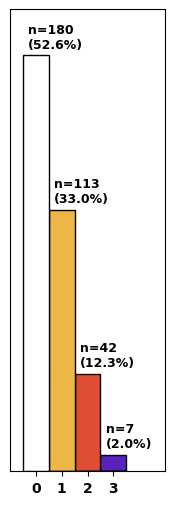

In [11]:
_text_hpad = 2  # in data units
fig, ax = plt.subplots(figsize=(2, 6))
sns.histplot(reach_plot, x="reach_base",
             hue="reach_base", palette=REACH_COLORS,
             bins=[-0.5, 0.5, 1.5, 2.5, 3.5],
             alpha=1, legend=False, ax=ax)
ax.set_xticks([0, 1, 2, 3])
[label.set_fontweight('bold') for label in ax.get_xticklabels()]
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])
ax.invert_yaxis()
ax.set_ylim(0, 200)  # hack for increasing plot bound size
ax.set_xlim(-1, 5)

for reach_val, subdict in reach_stats.to_dict(orient="index").items():
    count = subdict["count"]
    frac = subdict["fraction"]
    # if reach_val != 0:
    ax.text(reach_val-.3, count+_text_hpad,  f"n={count}\n({frac:.1%})",
            ha="left", va="bottom", fontsize=9, fontweight="bold")
    # else:
    # ax.text(count-_text_hpad, reach_val, f"{count}\n({frac:.1%})",
    # ha="right", va="center", fontsize=9, fontweight="bold")


# plt.tight_layout()
fig.savefig(OUT_DIR / "reach_histogram.pdf",
            bbox_inches="tight")
fig.savefig(OUT_DIR / "reach_histogram.jpg", dpi=300, bbox_inches="tight")

plt.show()

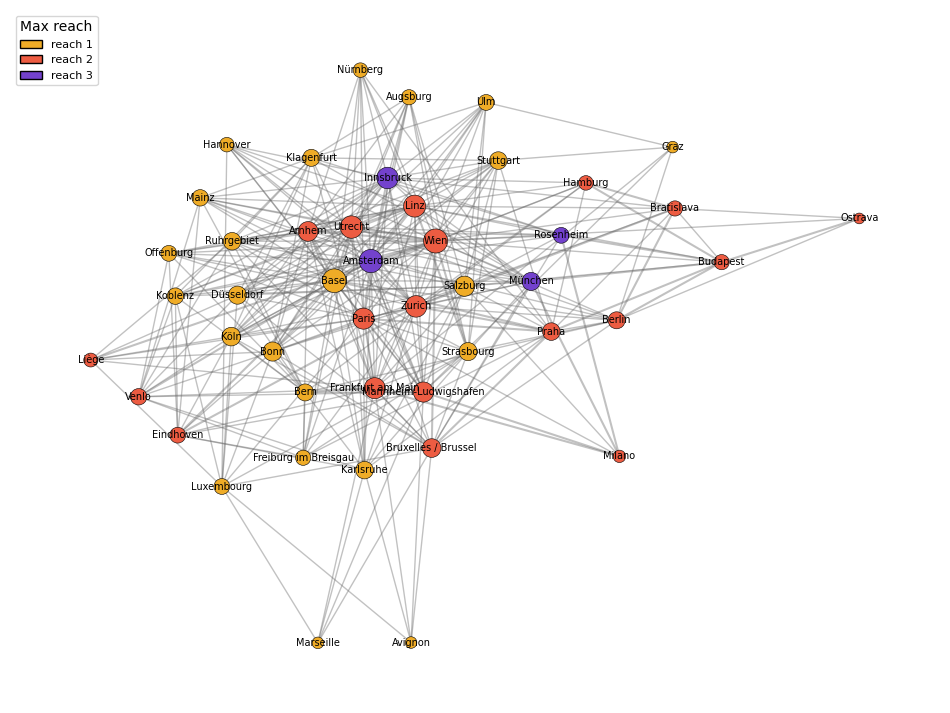

In [12]:
# --- Adjacency-threshold FUA graph (non-spatial) ---
from copy import deepcopy
import networkx as nx
from matplotlib.patches import Patch

# itinerary data (edge source) -- loaded here since data cell now only loads fua_gdf
it_base_df = pd.read_parquet(
    IN_DIR/"itineraries-enriched.parquet")

adjacency_lim = 1

# --- 1. Node set: per-FUA max adjacency > 2 (x=2) ---
direct = it_base_df[(it_base_df["n_trans"] == 0)
                    & (it_base_df["adjacency"] >= adjacency_lim)]
reach = direct.groupby("fua_src")["adjacency"].max()

fua_meta = fua_gdf.set_index("fua_id")
node_icc = fua_meta["icc"]

node_ids = reach[reach >= adjacency_lim].index
node_ids = node_ids[~node_ids.isin(EXCLUDE_FUAS)]
node_ids = node_ids[~node_ids.map(node_icc).isin(EXCLUDE_COUNTRIES)]
node_ids = set(node_ids)

# --- 2. Edges: direct OD pairs between selected nodes ---
edges = direct[
    direct["fua_src"].isin(node_ids) & direct["fua_trg"].isin(node_ids)
][["fua_src", "fua_trg", "adjacency"]].drop_duplicates(
    subset=["fua_src", "fua_trg"])

# --- 3. Build graph ---
G = nx.Graph()
for nid in node_ids:
    G.add_node(nid, reach=int(reach[nid]),
               popu=fua_meta.loc[nid, "popu"],
               name=fua_meta.loc[nid, "name"],
               icc=fua_meta.loc[nid, "icc"])
for _, r in edges.iterrows():
    G.add_edge(r["fua_src"], r["fua_trg"], adjacency=r["adjacency"])

min_deg = 10
G_plot = deepcopy(G)
G_plot.remove_nodes_from([n for n, d in G.degree() if d < min_deg])

# --- 4. Styling (existing reach palette) ---
REACH_COLORS = ["#ffffff", "#EFAC27", "#ed5c42", "#7342cd"]
color_map = {0: REACH_COLORS[0], 1: REACH_COLORS[1],
             2: REACH_COLORS[2], 3: REACH_COLORS[3]}
node_colors = [color_map[G_plot.nodes[n]["reach"]] for n in G_plot.nodes]
degrees = dict(G_plot.degree)
node_sizes = [20 + 10 * degrees[n] for n in G_plot.nodes]   # degree-scaled
edge_widths = [0.5 + 0.5 * G_plot[u][v]["adjacency"] for u, v in G_plot.edges]


# --- 5. One figure per layout ---

for layout_name, pos in [
    ("spring", nx.spring_layout(G_plot, seed=42, method="energy")),
    # ("mp", nx.multipartite_layout(G_plot)),
    # ("shell", nx.shell_layout(G_plot)),
]:
    fig, ax = plt.subplots(figsize=(12, 9))
    nx.draw_networkx_edges(G_plot, pos, ax=ax, width=edge_widths,
                           edge_color="#666666", alpha=0.4)
    nx.draw_networkx_nodes(G_plot, pos, ax=ax, node_color=node_colors,
                           node_size=node_sizes, edgecolors="black",
                           linewidths=0.4)
    nx.draw_networkx_labels(
        G_plot, pos, ax=ax,
        labels={n: G_plot.nodes[n]["name"] for n in G_plot.nodes}, font_size=7)
    ax.set_axis_off()
    handles = [Patch(facecolor=color_map[v], edgecolor="black",
                     label=f"reach {v}") for v in sorted(color_map)
               if v in {G_plot.nodes[n]["reach"] for n in G_plot.nodes}]
    ax.legend(handles=handles, title="Max reach", loc="upper left",
              fontsize=8)
    fig.savefig(OUT_DIR / f"fua_graph_{layout_name}.pdf", bbox_inches="tight")
    fig.savefig(OUT_DIR / f"fua_graph_{layout_name}.jpg", dpi=300,
                bbox_inches="tight")
    plt.show()

plot the scatter of degree distribution 
- per fua/country? 
- intl degree distr 
- and adjacency score 

In [13]:

g = G
deg_df = pd.DataFrame([
    {"fua_id": n, "name": G.nodes[n]["name"],
     "reach": G.nodes[n]["reach"], "degree": d}
    for n, d in G.degree()
])
deg_df["reach"] = deg_df["reach"].astype("category")
deg_df = deg_df.join(fua_gdf.popu, on="fua_id")

deg_df

,fua_id,name,reach,degree,popu
0,0,Aachen,1,5,551104
1,513,Rosenheim,3,21,321121
2,514,Rostock,1,4,418736
3,515,Rotterdam,3,8,1453642
4,517,Ruhrgebiet,1,15,5117230
...,...,...,...,...,...
157,484,Praha,2,22,2273406
158,499,Regensburg,1,5,464647
159,502,Reims,1,2,324514
160,504,Rennes,1,1,727733


In [14]:
adj_thres = 1

subset = it_base_df[(it_base_df.adjacency >= adj_thres)
                    & (it_base_df.n_trans == 0)]
subset

,path_id,src,trg,dep_win,time,gcd,dist,inveh_time,trans_time,n_trans,gtt,speed,fua_src,fua_trg,dist_od_stns,speed_od_stns,icc_src,icc_trg,adjacency
209,221795,37,24,2,21,91,106,21,0,0,21.0,302.857147,336,100,91.538796,261.539416,FR,BE,1
801,227264,97,73,2,29,78,94,29,0,0,29.0,194.482758,24,515,78.654653,162.733764,BE,NL,1
815,227611,13,12,1,29,50,57,29,0,0,29.0,117.931038,47,210,50.859463,105.226476,CH,DE,1
845,227152,3497,267,0,29,46,65,29,0,0,29.0,134.482758,24,90,46.189270,95.564006,BE,NL,1
870,226636,3497,267,1,29,46,65,29,0,0,29.0,134.482758,24,90,46.189270,95.564006,BE,NL,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112425,1007581,1994,2651,1,1261,793,1183,1261,0,0,1261.0,56.288658,475,17,791.414490,37.656518,CZ,FR,2
112426,1007582,77,2651,1,1264,587,723,1264,0,0,1264.0,34.319622,250,17,586.210770,27.826461,DE,FR,1
112590,1007606,181,226,1,1327,934,1431,1327,0,0,1327.0,64.702339,367,266,934.541717,42.255089,SE,AT,3
112638,1007618,3998,2651,1,1348,864,1271,1348,0,0,1348.0,56.572701,484,17,861.709266,38.355012,CZ,FR,2


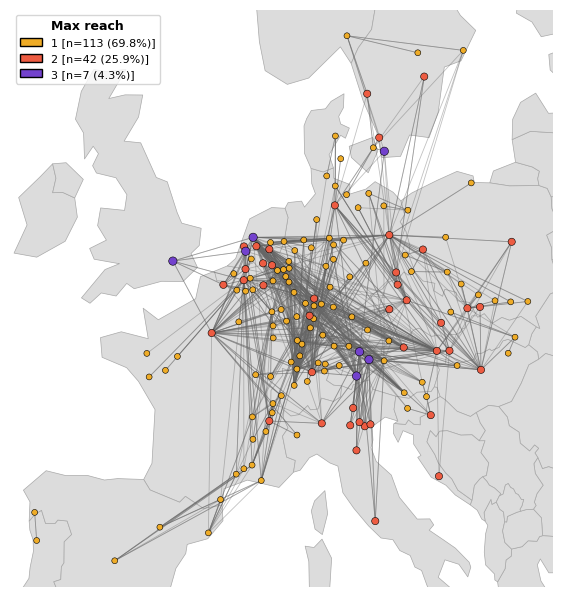

In [15]:
# --- Basemap + plot ---
k = 0
adj_thres = 1


# --- Fixed 4-colour reach map (reach 0-3); tune hex codes as needed ---
REACH_COLORS = ["#ffffff", "#EFAC27", "#ed5c42", "#7342cd"]  # reach 0,1,2,3
color_map = {0: REACH_COLORS[0], 1: REACH_COLORS[1],
             2: REACH_COLORS[2], 3: REACH_COLORS[3]}
reach_categories = sorted(color_map.keys())
legend_handles = []

# --- Degree filter: keep only G nodes with degree >= min_deg ---
reach_plot2 = reach_plot[(reach_plot["fua_id"].isin(
    G.nodes) & (reach_plot["reach_base"] >= adj_thres))].copy()
reach_plot2 = reach_plot2.copy()
reach_plot2["degree"] = reach_plot2["fua_id"].map(dict(G.degree))
reach_plot2 = reach_plot2[reach_plot2["degree"] >= k].copy()

fig, ax = make_basemap(basemap_path, crs=reach_plot2.crs,
                       bounds_source=reach_plot2, figsize=figsize_custom)

# --- OD direction lines: adjacency >= 1, direct, between surviving nodes ---
surviving_ids = set(reach_plot2["fua_id"])
od_lines = it_base_df[
    it_base_df["fua_src"].isin(surviving_ids)
    & it_base_df["fua_trg"].isin(surviving_ids)
    & (it_base_df["adjacency"] >= adj_thres)
    & (it_base_df["n_trans"] == 0)
][["fua_src", "fua_trg"]].drop_duplicates().copy()
# drop pairs touching excluded FUAs
od_lines = od_lines[
    (~od_lines["fua_src"].isin(EXCLUDE_FUAS))
    & (~od_lines["fua_trg"].isin(EXCLUDE_FUAS))
].copy()
# map endpoint FUA ids to centre points
fua_centre = fua_gdf.set_index("fua_id")["centre"]
od_lines["geom_src"] = od_lines["fua_src"].map(fua_centre)
od_lines["geom_trg"] = od_lines["fua_trg"].map(fua_centre)
od_lines = od_lines.dropna(subset=["geom_src", "geom_trg"]).copy()
od_lines["geometry"] = [
    LineString([s, t]) for s, t in zip(od_lines["geom_src"], od_lines["geom_trg"])
]
od_lines_gdf = gpd.GeoDataFrame(od_lines, geometry="geometry", crs=fua_gdf.crs)
od_lines_gdf.plot(ax=ax, color="#666666", alpha=0.4,
                  linewidth=0.6, zorder=1, aspect=None)

# --- Marker loop: one scatter per reach category ---

for v in reach_categories:
    sub = reach_plot2[reach_plot2["reach_base"] == v]
    if not sub.empty:
        ax.scatter(
            sub.centre.x,
            sub.centre.y,
            s=marker_sizes[v],
            c=[color_map[v]] * len(sub),
            edgecolor="black",
            linewidth=0.4,
        )
        _size = sub.shape[0]
        _frac = _size/reach_plot2.shape[0] * 100
        legend_handles.append(
            Patch(facecolor=color_map[v], edgecolor="black",
                  label=f"{v} [n={_size} ({_frac:.1f}%)]",
                  ))

# legend and titles
ax.legend(handles=legend_handles, title="Max reach",
          fontsize=8, title_fontproperties=dict(
              weight="bold", size=9,
          ),
          loc="upper left", frameon=True)
# ax.set_title(f"Max reach per FUA (n = {len(reach_plot2)})")

# --- Output ---
# fig.savefig(out_dir / "max_reach_map_degk.pdf", bbox_inches="tight")
# fig.savefig(out_dir / "max_reach_map_degk.jpg", dpi=300, bbox_inches="tight")

# plt.tight_layout()
plt.show()

In [16]:
# --- Subset check: reach-k G nodes vs mer == k edge-inferred nodeset ---
adj_thres = 1

direct_pairs = it_base_df[(it_base_df["n_trans"] == 0)
                          & (it_base_df["adjacency"] >= adj_thres)][
    ["fua_src", "fua_trg", "adjacency"]]

# mer = max over both directions; G.edges keeps only one direction
pair_df = pd.DataFrame({
    "u": np.minimum(direct_pairs["fua_src"], direct_pairs["fua_trg"]),
    "v": np.maximum(direct_pairs["fua_src"], direct_pairs["fua_trg"]),
    "adjacency": direct_pairs["adjacency"],
})
mer = pair_df.groupby(["u", "v"])["adjacency"].max().reset_index(name="mer")
mer = mer[mer["u"].isin(G.nodes) & mer["v"].isin(G.nodes)]

outside_by_k = {}
for k in (1, 2, 3):
    R_k = {n for n, d in G.nodes(data=True) if d["reach"] == k}
    sel = mer[mer["mer"] == k]
    E_k = set(sel["u"]) | set(sel["v"])
    outside_by_k[k] = R_k - E_k
    print(
        f"reach {k}: {len(outside_by_k[k])} of {len(R_k)} FUAs outside edge-inferred nodeset")

reach 1: 0 of 113 FUAs outside edge-inferred nodeset
reach 2: 0 of 42 FUAs outside edge-inferred nodeset
reach 3: 0 of 7 FUAs outside edge-inferred nodeset


mer == 1: 598 edges, 161 nodes


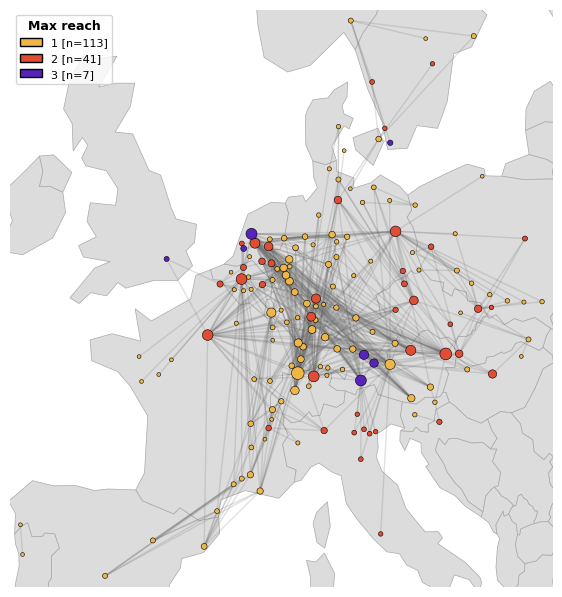

mer == 2: 95 edges, 62 nodes


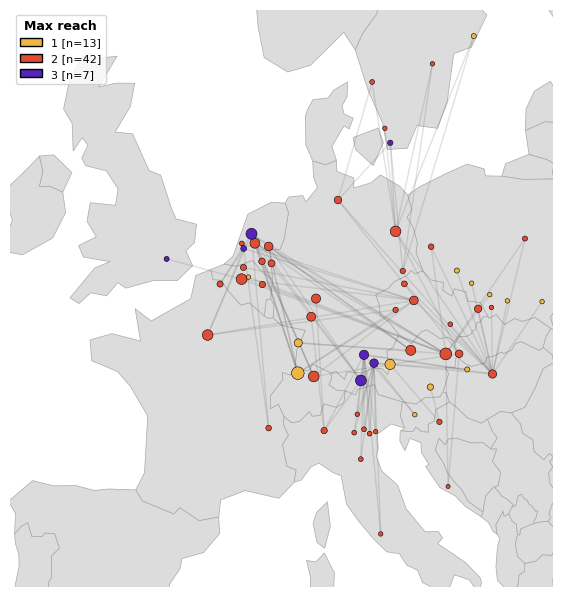

mer == 3: 6 edges, 9 nodes


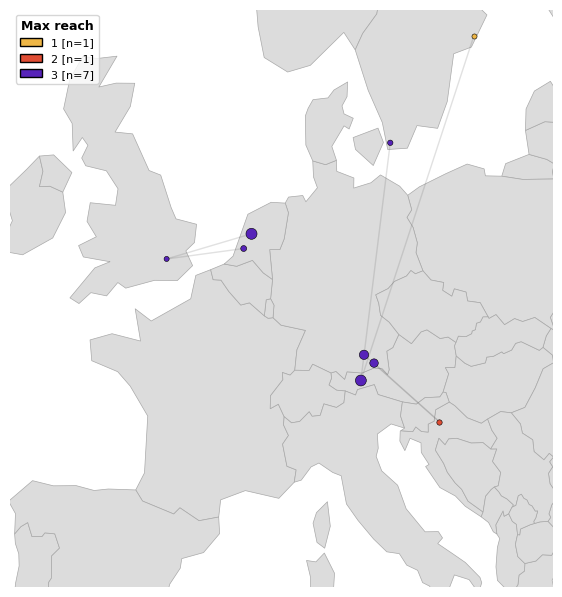

In [17]:
# --- Geographic reach-k edge maps: one panel per k (mer == k) ---
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

EDGE_LINEWIDTH = 1.0
REACH_COLORS = ["#ffffff", "#EEB646", "#df4d34",
                "#5723b9"]  # matches max_reach_map cell
color_map = {0: REACH_COLORS[0], 1: REACH_COLORS[1],
             2: REACH_COLORS[2], 3: REACH_COLORS[3]}
NODE_SIZE_BY_DEGREE = True
DEGREE_SIZE_BASE = 6.0
DEGREE_SIZE_INCREMENT = 1.5
deg_map = dict(G.degree)  # total G degree, all reach levels

fua_centre = fua_gdf.set_index("fua_id")["centre"]

# shared extent: G nodes with reach_base >= 1, no degree filter
extent_df = reach_plot[reach_plot["fua_id"].isin(G.nodes)
                       & (reach_plot["reach_base"].fillna(0) >= 1)].copy()


for k in (1, 2, 3):
    sel = mer[mer["mer"] == k].copy()
    sel["pu"] = sel["u"].map(fua_centre)
    sel["pv"] = sel["v"].map(fua_centre)
    sel = sel.dropna(subset=["pu", "pv"])
    node_ids = set(sel["u"]) | set(sel["v"])
    nodes_df = extent_df[extent_df["fua_id"].isin(node_ids)]

    fig, ax = make_basemap(basemap_path, crs=extent_df.crs,
                           bounds_source=extent_df, figsize=figsize_custom,
                           pad_frac=0.02)

    segments = [[(p.x, p.y), (q.x, q.y)]
                for p, q in zip(sel["pu"], sel["pv"])]
    ax.add_collection(LineCollection(segments, colors="dimgray", alpha=0.2,
                                     linewidths=EDGE_LINEWIDTH, zorder=1))

    legend_handles = []
    for v in sorted(nodes_df["reach_base"].dropna().unique()):
        v = int(v)
        sub = nodes_df[nodes_df["reach_base"] == v]
        if NODE_SIZE_BY_DEGREE:
            node_s = DEGREE_SIZE_BASE + DEGREE_SIZE_INCREMENT * \
                sub["fua_id"].map(deg_map).fillna(0).to_numpy()
        else:
            node_s = marker_sizes[v]
        ax.scatter(sub.centre.x, sub.centre.y, s=node_s,
                   c=[color_map[v]] * len(sub), edgecolor="black",
                   linewidth=0.4, zorder=2)
        # ax.scatter(sub.centre.x, sub.centre.y, s=marker_sizes[v],
        #            c=[color_map[v]] * len(sub), edgecolor="black",
        #            linewidth=0.4, zorder=2)
        legend_handles.append(
            Patch(facecolor=color_map[v], edgecolor="black",
                  label=f"{v} [n={len(sub)}]"))
    # legend_handles.append(
        # Line2D([0], [0], color=color_map[k], linewidth=EDGE_LINEWIDTH,
        #    label=f"edge mer={k} [n={len(sel)}]"))

    ax.legend(handles=legend_handles, title="Max reach", fontsize=8,
              title_fontproperties=dict(weight="bold", size=9),
              loc="upper left", frameon=True)

    fig.savefig(OUT_DIR / f"max_reach_map_edge{k}.pdf", bbox_inches="tight")
    fig.savefig(OUT_DIR / f"max_reach_map_edge{k}.jpg", dpi=300,
                bbox_inches="tight")
    print(f"mer == {k}: {len(sel)} edges, {len(nodes_df)} nodes")
    plt.show()

population: 353 | reach>0: 162 | G nodes: 162


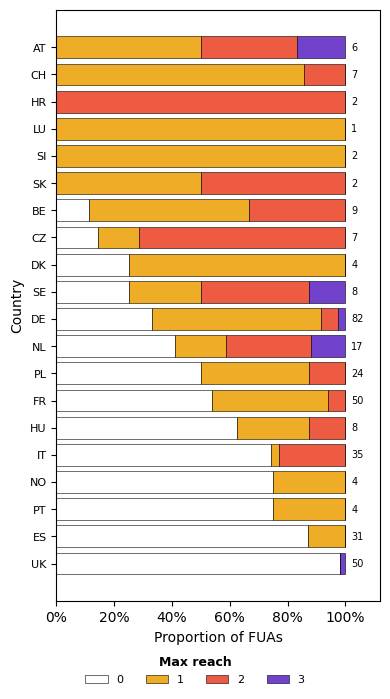

In [18]:
# --- Per-country reach proportion, 100% stacked horizontal bars ---
from matplotlib.ticker import PercentFormatter

REACH_BINS = [0, 1, 2, 3]
REACH_BIN_COLORS = ["#ffffff", "#EFAC27",
                    "#ed5c42", "#7342cd"]  # graph palette

pop = fua_gdf[["fua_id", "icc"]].copy()
pop = pop[~pop["icc"].isin(EXCLUDE_COUNTRIES)
          & ~pop["fua_id"].isin(EXCLUDE_FUAS)].copy()
pop["reach"] = pop["fua_id"].map(
    dict(G.nodes(data="reach"))).fillna(0).astype(int)

if pop["reach"].max() > max(REACH_BINS):
    raise ValueError(
        f"Max reach {pop['reach'].max()} exceeds palette (0-3)")

n_by_icc = pop["icc"].value_counts()
props = (pd.crosstab(pop["icc"], pop["reach"], normalize="index")
         .reindex(columns=REACH_BINS, fill_value=0))
order = props.sort_values(by=0, ascending=True, kind="stable").index.tolist()
props = props.loc[order]
assert np.allclose(props.sum(axis=1), 1.0)
print(
    f"population: {len(pop)} | reach>0: {(pop['reach'] > 0).sum()} | G nodes: {G.number_of_nodes()}")

fig, ax = plt.subplots(figsize=(4, 7))
y = np.arange(len(order))
left = np.zeros(len(order))
for r, col in zip(REACH_BINS, REACH_BIN_COLORS):
    vals = props[r].to_numpy()
    ax.barh(y, vals, left=left, height=0.8, color=col,
            edgecolor="black", linewidth=0.4, label=str(r))
    left += vals

# total in-scope FUA count right of each bar
for yi, icc in zip(y, order):
    ax.text(1.02, yi, f"{n_by_icc[icc]}", ha="left",
            va="center", fontsize=7)

ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=8)
ax.invert_yaxis()  # first country (lowest reach-0 share) at top
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Country")
ax.set_xlabel("Proportion of FUAs")

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, title="Max reach", fontsize=8,
           title_fontproperties=dict(weight="bold", size=9),
           loc="lower center", bbox_to_anchor=(0.5, 0.0),
           ncol=len(REACH_BINS), frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig(OUT_DIR / "country_reach_hist.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "country_reach_hist.jpg", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# it_base_df[(it_base_df.adjacency == 2) & (it_base_df.icc_src.isin(
#     ["FR", "CZ"])) & (it_base_df.icc_trg.isin(["FR", "CZ"]))]

modification plan
- number of source fuas per country.
- on diagonal have the number of international-servicing fuas
- plot as edged boxes the adjacent countries without links (missing)


In [20]:
# # --- Directed country-country heatmap: border + intensity square ---
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.patches import Patch, Rectangle

# adj_thres = 1
# diag_colour = "#353535"

# # --- 1. Country universe: reach_plot countries (post-exclusion), alphabetical ---
# fua_icc = fua_gdf.set_index("fua_id")["icc"]
# # countries = sorted(reach_plot["icc"].unique())
# countries = ["PT", "ES", "UK", "BE", "LU", "NL", "FR", "DE",
#              "AT", "CH", "CZ", "PL", "IT", "HU", "SK",  "SI", "HR", "DK", "SE", "NO",]
# cc_idx = {cc: i for i, cc in enumerate(countries)}
# m = len(countries)

# adj_thres = 1

# subset = it_base_df[(it_base_df.adjacency >= adj_thres)
#                     & (it_base_df.n_trans == 0)].copy()
# subset["fua_pair"] = subset[["fua_src", "fua_trg"]].apply(
#     tuple, axis=1).astype("category")
# subset = subset.drop_duplicates(subset="fua_pair")

# # # --- 2. Directed aggregation from subset (rows = from, columns = to) ---

# cc_src = subset["fua_src"].map(fua_icc)
# cc_trg = subset["fua_trg"].map(fua_icc)

# C = np.zeros((m, m), dtype=int)   # distinct directed pair counts
# R = np.zeros((m, m), dtype=int)   # max adjacency per pair
# for s, t, a in zip(cc_src, cc_trg, subset["adjacency"]):
#     if s in cc_idx and t in cc_idx:
#         i, j = cc_idx[s], cc_idx[t]
#         C[i, j] += 1
#         if a > R[i, j]:
#             R[i, j] = a

# # --- 3. Asymmetry mask: |C - C.T| >= 0.25 * max(C, C.T), pair-level ---
# max_pair = np.maximum(C, C.T)
# asym = (np.abs(C - C.T) >= 0.25 * max_pair) & (max_pair > 0)

# # --- 4. RGB background: white for linked, grey diagonal, white no-link ---
# REACH_COLORS = ["#ffffff", "#EFAC27", "#ed5c42", "#7342cd"]
# color_map = {0: REACH_COLORS[0], 1: REACH_COLORS[1],
#              2: REACH_COLORS[2], 3: REACH_COLORS[3]}


# def _hex_to_rgb(h):
#     h = h.lstrip("#")
#     return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


# white = _hex_to_rgb("#ffffff")
# grey = _hex_to_rgb(diag_colour)
# rgb = np.full((m, m, 3), white)
# for i in range(m):
#     for j in range(m):
#         if i == j:
#             rgb[i, j] = grey

# # --- 5. Plot ---
# fig, ax = plt.subplots(figsize=(7, 7))
# ax.imshow(rgb, interpolation="nearest", aspect="equal")

# ax.set_xticks(range(m))
# ax.set_yticks(range(m))
# ax.set_xticklabels(countries, fontsize=9, rotation=90)
# ax.set_yticklabels(countries, fontsize=9)

# # --- 6. Overlays: adjacency border + count text (bold if asymmetric) ---
# for i in range(m):
#     for j in range(m):
#         if C[i, j] > 0:
#             # border: adjacency colour
#             ax.add_patch(Rectangle(
#                 (j - 0.5, i - 0.5), 1, 1,
#                 facecolor=color_map[R[i, j]],
#                 edgecolor="none"))
#             # count text on top
#             txt_color = "black" if (
#                 R[i, j] < 3 and i != j) else "white"  # TODO:hardcode
#             ax.text(j, i, str(C[i, j]), ha="center", va="center",
#                     fontsize=8, color=txt_color,
#                     fontweight="bold" if asym[i, j] else "normal")
#         elif asym[i, j]:
#             # one-way link: explicit bold 0 on white background
#             ax.text(j, i, "0", ha="center", va="center",
#                     fontsize=8, color="black", fontweight="bold")

# # legend: adjacency border swatches, white = no link, grey = diagonal
# handles = [
#     Patch(facecolor=color_map[v], label=f"adj={v}") for v in (1, 2, 3)
# ]
# # handles.append(Patch(facecolor="#ffffff", edgecolor="black",
# #  label="no link"))
# handles.append(Patch(facecolor=diag_colour, label="(diagonal)"))
# ax.legend(handles=handles, title="Link\nadjacency",
#           fontsize=8, title_fontproperties=dict(weight="bold", size=9),
#           loc="upper right", frameon=True)

# # --- 7. Output ---
# fig.savefig(OUT_DIR / "country_heatmap.pdf", bbox_inches="tight")
# fig.savefig(OUT_DIR / "country_heatmap.jpg", dpi=300, bbox_inches="tight")
# plt.show()

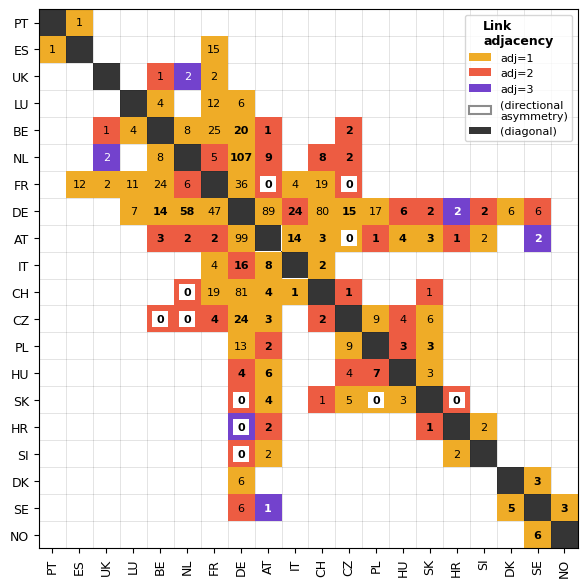

In [21]:
# --- Directed country-country heatmap: hollow one-way cells + base grid ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

diag_colour = "#353535"
hollow_edge = "#8c8c8c"
INSET = 0.2
adj_thres = 1

# --- 1. Country universe ---
fua_icc = fua_gdf.set_index("fua_id")["icc"]
countries = ["PT", "ES", "UK", "LU", "BE", "NL", "FR", "DE",
             "AT", "IT", "CH", "CZ", "PL", "HU", "SK", "HR", "SI", "DK", "SE", "NO"]
cc_idx = {cc: i for i, cc in enumerate(countries)}
m = len(countries)

subset = it_base_df[(it_base_df.adjacency >= adj_thres)
                    & (it_base_df.n_trans == 0)].copy()
subset["fua_pair"] = subset[["fua_src", "fua_trg"]].apply(
    tuple, axis=1).astype("category")
subset = subset.drop_duplicates(subset="fua_pair")

# --- 2. Directed aggregation (rows = from, columns = to) ---
cc_src = subset["fua_src"].map(fua_icc)
cc_trg = subset["fua_trg"].map(fua_icc)

C = np.zeros((m, m), dtype=int)   # distinct directed pair counts
R = np.zeros((m, m), dtype=int)   # max adjacency per pair
for s, t, a in zip(cc_src, cc_trg, subset["adjacency"]):
    if s in cc_idx and t in cc_idx:
        i, j = cc_idx[s], cc_idx[t]
        C[i, j] += 1
        if a > R[i, j]:
            R[i, j] = a

# --- 3. Masks: hollow = one-way link, asym = bold count ---
hollow = (R == 0) & (R.T > 0)
max_pair = np.maximum(C, C.T)
asym = (np.abs(C - C.T) >= 0.25 * max_pair) & (max_pair > 0)

# --- 4. Colours and RGB background ---
REACH_COLORS = ["#ffffff", "#EFAC27", "#ed5c42", "#7342cd"]
color_map = {k: c for k, c in enumerate(REACH_COLORS)}


def _hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


rgb = np.ones((m, m, 3))
for i in range(m):
    rgb[i, i] = _hex_to_rgb(diag_colour)

# --- 5. Plot ---
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(rgb, interpolation="nearest", aspect="equal")

ax.set_xticks(range(m))
ax.set_yticks(range(m))
ax.set_xticklabels(countries, fontsize=9, rotation=90)
ax.set_yticklabels(countries, fontsize=9)

# base grid, drawn under the patches
ax.set_xticks(np.arange(-0.5, m, 1), minor=True)
ax.set_yticks(np.arange(-0.5, m, 1), minor=True)
ax.grid(which="minor", color="#000000", alpha=0.15, linewidth=0.5)
ax.tick_params(which="minor", length=0)
ax.set_axisbelow(True)

# --- 6. Overlays: solid links, hollow one-way cells, counts on top ---
for i in range(m):
    for j in range(m):
        x0, y0 = j - 0.5, i - 0.5
        if R[i, j] > 0:
            ax.add_patch(Rectangle((x0, y0), 1, 1,
                                   facecolor=color_map[R[i, j]],
                                   edgecolor="none", zorder=1))
        elif hollow[i, j]:
            # outer colour comes from the reverse direction's adjacency
            ax.add_patch(Rectangle((x0, y0), 1, 1,
                                   facecolor=color_map[R[j, i]],
                                   edgecolor="none", zorder=1))
            ax.add_patch(Rectangle((x0 + INSET, y0 + INSET),
                                   1 - 2 * INSET, 1 - 2 * INSET,
                                   facecolor="#ffffff",
                                   edgecolor="none", zorder=2))

        if C[i, j] > 0:
            txt_color = "black" if (
                R[i, j] < 3 and i != j) else "white"  # TODO:hardcode
            ax.text(j, i, str(C[i, j]), ha="center", va="center",
                    fontsize=8, color=txt_color,
                    fontweight="bold" if asym[i, j] else "normal", zorder=4)
        elif asym[i, j]:
            # one-way link with no count: explicit bold 0
            ax.text(j, i, "0", ha="center", va="center",
                    fontsize=8, color="black", fontweight="bold", zorder=4)

# --- 7. Legend ---
handles = [Patch(facecolor=color_map[v], label=f"adj={v}") for v in (1, 2, 3)]
handles.append(Patch(facecolor="#ffffff", edgecolor=hollow_edge,
                     linewidth=1.5, label="(directional\nasymmetry)"))
handles.append(Patch(facecolor=diag_colour, label="(diagonal)"))
ax.legend(handles=handles, title="Link\nadjacency",
          fontsize=8, title_fontproperties=dict(weight="bold", size=9),
          loc="upper right", frameon=True)

# --- 8. Output ---
fig.savefig(OUT_DIR / "country_heatmap.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "country_heatmap.jpg", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
subset = it_base_df[(it_base_df.adjacency >= adj_thres)
                    & (it_base_df.n_trans == 0)].copy()
subset["fua_pair"] = subset[["fua_src", "fua_trg"]].apply(
    tuple, axis=1).astype("category")

# subset.drop_duplicates(subset="fua_pair")
subset

,path_id,src,trg,dep_win,time,gcd,dist,inveh_time,trans_time,n_trans,gtt,speed,fua_src,fua_trg,dist_od_stns,speed_od_stns,icc_src,icc_trg,adjacency,fua_pair
209,221795,37,24,2,21,91,106,21,0,0,21.0,302.857147,336,100,91.538796,261.539416,FR,BE,1,"(336, 100)"
801,227264,97,73,2,29,78,94,29,0,0,29.0,194.482758,24,515,78.654653,162.733764,BE,NL,1,"(24, 515)"
815,227611,13,12,1,29,50,57,29,0,0,29.0,117.931038,47,210,50.859463,105.226476,CH,DE,1,"(47, 210)"
845,227152,3497,267,0,29,46,65,29,0,0,29.0,134.482758,24,90,46.189270,95.564006,BE,NL,1,"(24, 90)"
870,226636,3497,267,1,29,46,65,29,0,0,29.0,134.482758,24,90,46.189270,95.564006,BE,NL,1,"(24, 90)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112425,1007581,1994,2651,1,1261,793,1183,1261,0,0,1261.0,56.288658,475,17,791.414490,37.656518,CZ,FR,2,"(475, 17)"
112426,1007582,77,2651,1,1264,587,723,1264,0,0,1264.0,34.319622,250,17,586.210770,27.826461,DE,FR,1,"(250, 17)"
112590,1007606,181,226,1,1327,934,1431,1327,0,0,1327.0,64.702339,367,266,934.541717,42.255089,SE,AT,3,"(367, 266)"
112638,1007618,3998,2651,1,1348,864,1271,1348,0,0,1348.0,56.572701,484,17,861.709266,38.355012,CZ,FR,2,"(484, 17)"


In [23]:
# --- Join: degree, reach, population per international-servicing FUA ---
# universe: endpoints of direct (n_trans==0), adjacency>0 itineraries,
# after exclusions; degree = undirected distinct neighbours;
# reach = max adjacency over src OR trg itineraries (symmetric).

fua_icc = fua_gdf.set_index("fua_id")["icc"]

direct = it_base_df[(it_base_df["n_trans"] == 0)
                    & (it_base_df["adjacency"] > 0)].copy()

# exclusions on both endpoints
ok_src = (~direct["fua_src"].isin(EXCLUDE_FUAS)
          & ~direct["fua_src"].map(fua_icc).isin(EXCLUDE_COUNTRIES))
ok_trg = (~direct["fua_trg"].isin(EXCLUDE_FUAS)
          & ~direct["fua_trg"].map(fua_icc).isin(EXCLUDE_COUNTRIES))
direct = direct[ok_src & ok_trg]

# universe: union of endpoints
universe = sorted(set(direct["fua_src"]) | set(direct["fua_trg"]))

# undirected degree: distinct neighbours per FUA
neighbours = (
    pd.concat([
        direct[["fua_src", "fua_trg"]],
        direct[["fua_trg", "fua_src"]].rename(
            columns={"fua_trg": "fua_src", "fua_src": "fua_trg"}),
    ])
    .drop_duplicates()
    .groupby("fua_src")["fua_trg"].nunique()
)

# reach: max adjacency where FUA is src or trg
reach = pd.concat([
    direct.groupby("fua_src")["adjacency"].max(),
    direct.groupby("fua_trg")["adjacency"].max(),
]).groupby(level=0).max()

fua_scatter = (
    fua_gdf.loc[fua_gdf["fua_id"].isin(universe),
                ["fua_id", "name", "icc", "popu"]]
    .set_index("fua_id")
)
fua_scatter["degree"] = fua_scatter.index.map(neighbours).fillna(0).astype(int)
fua_scatter["reach"] = fua_scatter.index.map(
    reach).fillna(0).astype(int)
fua_scatter = fua_scatter[fua_scatter["reach"] > 0]   # reach==0 drop (guard)

# --- validation ---
assert fua_scatter.index.is_unique
assert (fua_scatter["degree"] >= 1).all()
print(f"n FUAs: {len(fua_scatter)}")
print(f"max reach: {fua_scatter['reach'].max()} (palette guard if > 3)")
display(fua_scatter["reach"].value_counts().sort_index())

n FUAs: 174
max reach: 3 (palette guard if > 3)


reach
1    108
2     57
3      9
Name: count, dtype: int64

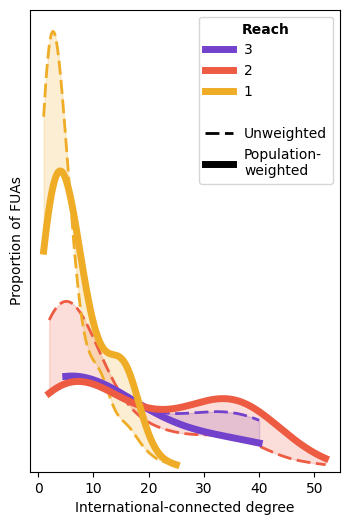

In [25]:
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(4, 6))
sns.kdeplot(fua_scatter, x="degree", hue="reach",
            common_norm=False,
            palette=REACH_COLORS[1:],
            cut=0, linewidth=2,
            # log_scale=(True, False),
            linestyle=(0, (5, 2)),
            ax=ax
            # common_grid=False
            )
sns.kdeplot(fua_scatter, x="degree", hue="reach",
            weights="popu",
            common_norm=False,
            # log_scale=(True, False),
            palette=REACH_COLORS[1:],
            cut=0, linewidth=5,
            hue_order=[1, 2, 3],
            ax=ax
            )

# --- Extract & shade between KDE curves (unweighted vs weighted pairs) ---
# ax = plt.gca()
lines = ax.lines
n_hues = len(fua_scatter.reach.unique())  # number of reach categories
handles = []

# Pair unweighted (first 3 lines) with weighted (next 3 lines) by hue order
for i in range(n_hues):
    line_unweighted = lines[i]
    line_weighted = lines[n_hues + i]

    # Extract x, y data
    x_uw = line_unweighted.get_xdata()
    y_uw = line_unweighted.get_ydata()
    x_w = line_weighted.get_xdata()
    y_w = line_weighted.get_ydata()

    # Shade between curves (align on x if needed)
    color = line_weighted.get_color()
    ax.fill_between(x_w, y_uw, y_w, alpha=0.2, color=color, zorder=0)

    handles.append(line_weighted)

# Optional: redraw lines on top for crisp edges
# for line in lines:
    # line.set_zorder(10)
# Deactivate y-ticks
ax.set_yticks([])

# Set labels
ax.set_ylabel("Proportion of FUAs")
ax.set_xlabel("International-connected degree")

# # Create custom Line2D objects for the linestyles
custom_lines = [
    Line2D([0], [0], color='none'),
    Line2D([0], [0], linestyle=(0, (5, 2)), color='black', linewidth=2),
    Line2D([0], [0], linestyle='-', color='black', linewidth=5)
]
combined_handles = handles + custom_lines
combined_labels = ["3", "2", "1", "", 'Unweighted', 'Population-\nweighted']

# # Create legend with title
ax.legend(combined_handles, combined_labels,
          title="Reach", title_fontproperties=dict(weight="bold"),
          loc='best')

plt.savefig(OUT_DIR/"reach_deg_distr.pdf", bbox_inches="tight")
plt.savefig(OUT_DIR/"reach_deg_distr.jpg", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# fua_scatter["reach_cat"] = fua_scatter["is_reach"].astype("category")

# sns.jointplot(fua_scatter, x="popu", y="degree",
#               hue="reach_cat",
#               kind="scatter",
#               palette=REACH_COLORS[1:],

#               marginal_kws=dict(
#                   fill=False, cut=0, common_norm=False,
#                   weights=fua_scatter["popu"]
#               ),
#               joint_kws=dict(
#                   size_norm=(1000000, 10000000),
#                   size=fua_scatter["popu"]
#               )

#               )
# ax = plt.gca()
# ax.set(xscale="log",
#        yscale="log")
# plt.show()

KeyError: 'is_reach'

how to normalise kde to have same total area?
- how to interpret this?    